# TinyStories model: inference

Load a trained checkpoint and generate stories with it. Run the cells top to bottom.

**Kernel:** run `make kernel` once from the repo root, then pick **Python (tinystories-lm)**.

To use a different model, change the **Settings** cell and run everything again.

## Settings

In [1]:
CHECKPOINT = "runs/pretrain-full/ckpt_best.pt"  # relative to the repo root
DATA_DIR = "data/full"   # provides the tokenizer; must be the one the checkpoint was trained with
DEVICE = "cpu"           # for a 10M model, cpu generates ~9x faster than mps (per-op GPU overhead dominates)
SEED = 1337              # same seed + same settings = same story

## Setup

In [2]:
import sys
import textwrap
from pathlib import Path

# Find the repo root so the notebook works from any folder inside the repo.
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Open this notebook from inside the gibberish-1 repo")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import torch

from tinystories_lm.data.tokenizer import BPETokenizer
from tinystories_lm.inference.generate import generate_text, profile_generation
from tinystories_lm.utils.checkpoint import assert_tokenizer_match, load_model_from_checkpoint
from tinystories_lm.utils.device import resolve_device
from tinystories_lm.utils.seed import seed_everything

print("repo root:", ROOT)

repo root: /Users/nikhilkunapareddy/Documents/gibberish-1


## Load the model

In [3]:
device_info = resolve_device(DEVICE)
model, ckpt = load_model_from_checkpoint(ROOT / CHECKPOINT, device_info.device)
tokenizer = BPETokenizer.load(ROOT / DATA_DIR)
assert_tokenizer_match(ckpt, tokenizer.hash(), where=CHECKPOINT)  # fails loudly on a mismatched tokenizer

print(model.describe())
# metrics["val_loss"] is the validation loss measured at this checkpoint's step.
# (Not ckpt["best_val_loss"]: checkpoints saved before the CheckpointManager fix record a stale value.)
val = (ckpt.get("metrics") or {}).get("val_loss")
val_txt = f"{val:.4f}" if val is not None else "n/a"
print(f"\nstage={ckpt['stage']}  step={ckpt['step']}  val_loss={val_txt}  device={device_info.type}")

Transformer[tiny-10m]: n_layer=6 n_head=8 d_model=384 hidden=1024 vocab=8192 block=512 tied=True
  params total           13,767,552  (13.77M)
  params non-embedding   10,621,824  (10.62M)
    embedding             3,145,728
    attention             3,538,944
    mlp                   7,077,888
    norm                      4,992

stage=pretrain  step=3000  val_loss=1.5738  device=cpu


In [4]:
def tell(prompt="Once upon a time", max_new_tokens=200, temperature=0.8, top_k=40, top_p=0.95,
         greedy=False, num_samples=1, seed=SEED, width=100, model=model):
    """Generate from a prompt and print the story wrapped to `width` characters.

    Generation stops at the end-of-story token or after `max_new_tokens`.
    """
    seed_everything(seed)
    gens = generate_text(model, tokenizer, prompt, max_new_tokens=max_new_tokens,
                         temperature=temperature, top_k=top_k, top_p=top_p, greedy=greedy,
                         num_samples=num_samples, device_info=device_info)
    for i, g in enumerate(gens, 1):
        if num_samples > 1:
            print(f"--- sample {i}/{num_samples} ---")
        for para in g.text.split("\n"):
            print(textwrap.fill(para, width) if para.strip() else "")
        print(f"[{g.n_new_tokens} tokens, {g.tokens_per_sec:.0f} tok/s]\n")

## 1. Tell a story

In [5]:
tell("Once upon a time")

Once upon a time, there was a little girl named Lily. She loved to play with her toys and her
friends. One day, Lily's mommy took her to the park to play. Lily was so excited! She ran around and
had so much fun.
Suddenly, Lily got lost and started to cry. Her mommy hugged her and said, "Don't worry, we'll find
your way back home." They walked and walked until they found a big tree. It was very tall and had
branches that looked like a ladder.
Lily was so happy to see the ladder and thanked her mommy for taking her there. She ran back home,
excited to tell her friends all about her adventure.
[136 tokens, 415 tok/s]



## 2. Your own prompt

Edit the prompt and run the cell. The model only knows simple children's stories,
so prompts in that style work best. Change `seed` to get a different story.

In [6]:
tell("Lily found a tiny door in the garden. She", num_samples=2)

--- sample 1/2 ---
Lily found a tiny door in the garden. She looked at the door and saw a small garden with a small
door. She opened the door and saw a big garden with flowers.
"Wow, look at this!" she said. "It is so pretty!"
Her mom came outside and saw her. "What are you doing?" she asked.
"I want to see what is in the garden, but I don't know how."
Lily nodded and said, "I want to go and see. Can you show me?"
Her mom smiled and took her hand. Together, they went to the garden and looked at the flowers. They
were all beautiful and beautiful.
"Wow, Lily, you are so good at looking at the flowers!" her mom said.
"Yes, she is! She is very pretty and healthy. Can I touch them?" Lily said.
"Sure, you can touch the flowers, but be careful. They are very fragile," her mom said.
Lily touched the flowers and felt
[200 tokens, 286 tok/s]

--- sample 2/2 ---
Lily found a tiny door in the garden. She put the key in the lock and turned it. The key started to
unlock and opened the door.
Inside w

## 3. Sampling settings

Same prompt and seed, different settings:

- **greedy** always picks the most likely next token. Safe, but tends to loop.
- **low temperature** stays close to greedy.
- **high temperature** (with top-k and top-p switched off) takes more risks and loses the thread sooner.

In [7]:
settings = {
    "greedy": dict(greedy=True),
    "temperature 0.5": dict(temperature=0.5),
    "temperature 0.8 (default)": dict(temperature=0.8),
    "temperature 1.2, no top-k/top-p": dict(temperature=1.2, top_k=0, top_p=1.0),
}
for name, kw in settings.items():
    print(f"=== {name} ===")
    tell("The little dog was hungry.", max_new_tokens=80, **kw)

=== greedy ===
The little dog was hungry. He looked around and saw a big tree. He ran to the tree and started to
climb. He climbed higher and higher until he reached the top.
The little dog was so happy. He had found a place to rest and he was very tired. He lay down and
closed his eyes. He was so tired that he fell asleep.
The little dog slept for a long time. When he
[80 tokens, 483 tok/s]

=== temperature 0.5 ===


The little dog was hungry. He looked around and saw a big tree. He thought that if he climbed the
tree, he would get a treat. So he climbed up the tree and reached the treat.
When he got to the treat, he saw a big, juicy apple. He took a bite and it was so yummy! He took
another bite and then another. He ate the apple and was happy.
The little
[80 tokens, 424 tok/s]

=== temperature 0.8 (default) ===
The little dog was hungry. He saw a big bowl of cereal on the table. He ran to the bowl and jumped
on it. He tried to bite the cereal with his teeth. But the cereal was too hot. The bowl broke and
the cereal spilled on the floor.
"Oh no!" Lily and Ben said. They looked at the mess. They saw the bowl and the cereal on the floor.
They were very angry
[80 tokens, 418 tok/s]

=== temperature 1.2, no top-k/top-p ===


The little dog was hungry. He saw a sack near the bench with a naughty look. He reached up and
panned out it.
The noisy dog ran towards it, sniffing around behind his big voice. The little dog tattered with
rins against his tough fist.
The song of gloss healed his whole cube. The messy little dog coughed and snarling with relief, his
wagging lips put his
[80 tokens, 381 tok/s]



## 4. What the model predicts next

The 10 most likely next tokens after a prompt, with their probabilities.
A leading space is part of the token (`' girl'` and `'girl'` are different tokens).

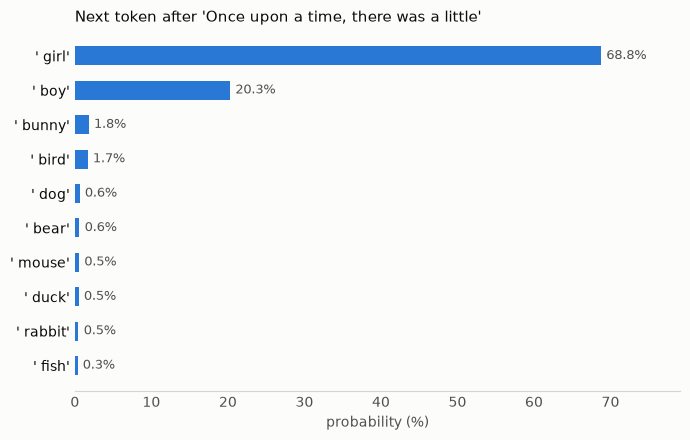

In [8]:
def next_token_probs(prompt, k=10):
    ids = torch.tensor([tokenizer.encode(prompt)], device=device_info.device)
    with torch.no_grad():
        logits, _ = model(ids, last_token_only=True)
    probs = torch.softmax(logits[0, -1].float(), dim=-1)
    top = torch.topk(probs, k)
    return [(tokenizer.decode([i]), p) for i, p in zip(top.indices.tolist(), top.values.tolist())]


def plot_next_tokens(prompt, k=10):
    preds = next_token_probs(prompt, k)[::-1]  # most likely at the top
    labels = [repr(tok) for tok, _ in preds]
    values = [p * 100 for _, p in preds]

    ink, ink_muted, surface, bar = "#0b0b0b", "#52514e", "#fcfcfb", "#2a78d6"
    fig, ax = plt.subplots(figsize=(7, 0.35 * k + 1), facecolor=surface)
    ax.set_facecolor(surface)
    ax.barh(labels, values, height=0.55, color=bar)
    for y, v in enumerate(values):
        ax.text(v + max(values) * 0.01, y, f"{v:.1f}%", va="center", fontsize=9, color=ink_muted)
    ax.set_title(f"Next token after {prompt!r}", loc="left", fontsize=11, color=ink)
    ax.set_xlabel("probability (%)", color=ink_muted)
    ax.set_xlim(0, max(values) * 1.15)
    ax.tick_params(colors=ink_muted, length=0)
    ax.tick_params(axis="y", labelcolor=ink, labelsize=10)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#d4d3cf")
    plt.tight_layout()
    plt.show()


plot_next_tokens("Once upon a time, there was a little")

## 5. How the model learned

The same prompt and seed, generated by checkpoints saved during training.

In [9]:
run_dir = (ROOT / CHECKPOINT).parent
paths = [run_dir / "ckpt_early.pt", *sorted(run_dir.glob("ckpt_step_*.pt"))]

for path in paths:
    m, c = load_model_from_checkpoint(path, device_info.device)
    print(f"=== step {c['step']} ===")
    tell("Once upon a time", max_new_tokens=60, model=m)
    del m

=== step 200 ===
Once upon a time, there was a little girl named Lily. She loved to play with her friend, but her mom
said, "That's a little girl named Lily. She liked to play in the park and see what was too late.
Lily was so happy that she could take a new toy and go
[60 tokens, 419 tok/s]



=== step 1000 ===
Once upon a time, there was a little girl named Lily. She loved to run and play outside with her
friends. One day, her mom told her they had to go to the park. Lily didn't want to go, but her mom
said it was important to stay safe.
As they were walking, Lily
[60 tokens, 420 tok/s]



=== step 2000 ===
Once upon a time, there was a little girl named Lily. She loved to draw pictures with her colorful
crayons. One day, she went to the park to play with her friends. She was having so much fun, but
then she saw her friend Emma's picture.
"Hi Emma! Look at my picture!"
[60 tokens, 409 tok/s]



=== step 3000 ===
Once upon a time, there was a little girl named Lily. She loved to play with her toys and her
friends. One day, Lily's mommy took her to the park to play. Lily was so excited! She ran around and
had so much fun.
Suddenly, Lily got lost and started to cry. Her
[60 tokens, 408 tok/s]



## 6. Speed: the KV cache

The KV cache stores attention keys and values from earlier tokens so each new token
only processes itself. Both paths must produce identical text.

In [10]:
stats = profile_generation(model, tokenizer, "Once upon a time", max_new_tokens=128,
                           device_info=device_info)
print(f"with KV cache:    {stats['with_cache']['tokens_per_sec']:>7} tok/s")
print(f"without KV cache: {stats['no_cache']['tokens_per_sec']:>7} tok/s")
print(f"speedup: {stats['speedup']}x   identical output: {stats['identical_output']}")

with KV cache:      495.3 tok/s
without KV cache:   121.8 tok/s
speedup: 4.07x   identical output: True
